# Preprocessing: candidate 5 km grid and chronological research tables

Sections 1–6 preserve the existing full-square lattice and all-downloaded-BIG candidate mask; this does not approve the mask scientifically. Section 7 uses the shared, source-validated preparation workflow instead of the legacy fixed-year joins and zero-filled detection calendar. Same-day labels remain UTC retrospective research, not an operational forecast. Existing legacy exports are preserved.


In [1]:
import hashlib
import json
from peatguard.study import find_root

import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
import pyproj
from pyproj import CRS, Geod, Transformer
import shapely
from shapely.geometry import mapping, shape
from shapely.ops import transform
from shapely.plotting import plot_polygon

ROOT = find_root()
BOUNDARY_PATH = ROOT / "data/raw/boundaries/big_kalimantan_provinces.geojson"
PEAT_PATH = ROOT / "data/raw/peatland/big_peta_lahan_gambut_kalimantan.geojson"
OUTPUT_DIR = ROOT / "data/interim/study_grid_5km"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 5 km grids (use meters cuz its more accurate than angles)
# Longitude and Latitude are angles, so degree spacing varies in ground distance.
CELL_M = 5_000
SOURCE_CRS = CRS.from_epsg(4326)  # downloaded GeoJSON longitude/latitude

# lat_0 and lon_0 centers the projection to kalimantan
GRID_CRS_PROJ = "+proj=laea +lat_0=0 +lon_0=114 +datum=WGS84 +units=m +no_defs"
GRID_CRS = CRS.from_proj4(GRID_CRS_PROJ)
to_grid = Transformer.from_crs(SOURCE_CRS, GRID_CRS, always_xy=True)
to_lonlat = Transformer.from_crs(GRID_CRS, SOURCE_CRS, always_xy=True)

## 1. Load unsimplified polygons and project into metres

Longitude/latitude degrees do not have a fixed length in kilometres. Use one
Lambert azimuthal equal-area (LAEA) projection centered at 114°E, 0°N for the
whole region, rather than joining grids from multiple UTM zones. Equal area
makes overlap fractions straightforward. Each square is exactly 5,000 m per
side **in this projection**; ground distances vary slightly. We measure that
variation below.

The province GeoJSON contains Z/M coordinates; discard those extra values.
Reject invalid or empty geometry rather than silently repairing source data.
Dissolve overlapping polygons to avoid counting the same area twice, and
restrict the candidate BIG mask to the province union. No simplified geometry
is used for grid creation, inclusion, or overlap calculations.

In [2]:
def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]


def load_polygons(path):
    document = json.loads(path.read_text(encoding="utf-8"))
    features = document["features"]
    geometries = np.array([
        shape({"type": feature["geometry"]["type"],
               "coordinates": keep_xy(feature["geometry"]["coordinates"])})
        for feature in features
    ], dtype=object)
    if not shapely.is_valid(geometries).all():
        raise ValueError(f"Invalid geometry in {path}")
    return features, geometries


province_features, province_ll = load_polygons(BOUNDARY_PATH)
peat_features, peat_ll = load_polygons(PEAT_PATH)
provinces = np.array([transform(to_grid.transform, g) for g in province_ll])
peat_polygons = np.array([transform(to_grid.transform, g) for g in peat_ll])
study_area = shapely.union_all(provinces)
mapped_union = shapely.union_all(peat_polygons)
mapped_in_study = shapely.intersection(mapped_union, study_area)

print("Provinces:", ", ".join(f["properties"]["WADMPR"] for f in province_features))
print(f"Candidate BIG polygons: {len(peat_features):,}")
print(f"Province union: {study_area.area / 1e6:,.1f} km²")
print(f"Dissolved candidate BIG mask within provinces: {mapped_in_study.area / 1e6:,.1f} km²")
print(f"Candidate BIG area outside provinces: {(mapped_union.area - mapped_in_study.area) / 1e6:,.1f} km²")

Provinces: Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan, Kalimantan Timur, Kalimantan Utara
Candidate BIG polygons: 146
Province union: 534,702.8 km²
Dissolved candidate BIG mask within provinces: 45,281.9 km²
Candidate BIG area outside provinces: 0.0 km²


## 2. Build a reproducible square lattice

Anchor the lattice at projected (0, 0), with cell edges at integer multiples of
5,000 m. Integer `grid_col` and `grid_row` identify a cell even if the study
extent changes later; rows increase **northward**. `cell_id` combines those
indices. The ConvLSTM tensors account for this direction by placing northern rows first.

Keep cells with **positive-area overlap** with the province union, including
coastal and international-border cells. Keep their full square geometry;
clipping squares would create irregular cells. `study_fraction` records the
part inside the provinces. Full-cell areas must not be summed to estimate land
or peat area.

For speed, calculate exact intersections in 100 km tiles. Because 100 km is
a multiple of 5 km, each square lies entirely in its assigned tile; no cell
is cut or moved by this calculation.

In [3]:
min_x, min_y, max_x, max_y = study_area.bounds
col_start, row_start = np.floor(np.array([min_x, min_y]) / CELL_M).astype(int)
col_stop, row_stop = np.ceil(np.array([max_x, max_y]) / CELL_M).astype(int)
cols, rows = np.meshgrid(np.arange(col_start, col_stop), np.arange(row_start, row_stop))
cols, rows = cols.ravel(), rows.ravel()
x0, y0 = cols * CELL_M, rows * CELL_M
candidates = shapely.box(x0, y0, x0 + CELL_M, y0 + CELL_M)

# Fast predicate first; calculate exact areas only for intersecting candidates.
shapely.prepare(study_area)
hits = shapely.intersects(study_area, candidates)
study_area_m2 = np.zeros(len(candidates))
def overlap_areas(squares, mask):
    """Exact overlay in 100 km tiles; keep the full source detail locally."""
    bounds = shapely.bounds(squares)
    tile_keys = np.floor(bounds[:, :2] / 100_000).astype(int)
    areas = np.zeros(len(squares))
    for tile_col, tile_row in np.unique(tile_keys, axis=0):
        selected = np.flatnonzero((tile_keys == [tile_col, tile_row]).all(axis=1))
        tile = shapely.box(tile_col * 100_000, tile_row * 100_000,
                           (tile_col + 1) * 100_000, (tile_row + 1) * 100_000)
        local_mask = shapely.intersection(mask, tile)
        if not local_mask.is_empty:
            areas[selected] = shapely.area(shapely.intersection(squares[selected], local_mask))
    return areas


study_area_m2[hits] = overlap_areas(candidates[hits], study_area)
keep = study_area_m2 > 0
cells = candidates[keep]
grid = pd.DataFrame({
    "cell_id": [f"kp5_c{c}_r{r}" for c, r in zip(cols[keep], rows[keep])],
    "grid_col": cols[keep], "grid_row": rows[keep],
    "x_min_m": x0[keep], "y_min_m": y0[keep],
    "x_center_m": x0[keep] + CELL_M / 2,
    "y_center_m": y0[keep] + CELL_M / 2,
    "cell_area_km2": CELL_M**2 / 1e6,
    "study_fraction": study_area_m2[keep] / CELL_M**2,
})
print(f"Bounding rectangle: {row_stop-row_start} rows × {col_stop-col_start} columns")
print(f"Cells overlapping Kalimantan: {len(grid):,}")

Bounding rectangle: 208 rows × 234 columns
Cells overlapping Kalimantan: 22,336


## 3. Flag candidate BIG intersections and measure coverage

`intersects_big_peatland` means that the full square intersects the dissolved
BIG mask **within Kalimantan**, including boundary-only touches.
`big_peatland_area_km2` measures the actual overlap;
`big_peatland_fraction` divides it by the full 25 km² square. Also retain
`has_positive_big_overlap` to distinguish any zero-area touches.

There is no minimum peat fraction at this stage. A flagged square may contain
mostly non-peat land or sea; the flag does not mean that every point in the
square is peatland. These columns let us inspect sensitivity before adopting
a final study-cell rule.

In [4]:
shapely.prepare(mapped_in_study)
intersects_big = shapely.intersects(mapped_in_study, cells)
overlap_m2 = np.zeros(len(cells))
overlap_m2[intersects_big] = overlap_areas(cells[intersects_big], mapped_in_study)
grid["intersects_big_peatland"] = intersects_big
grid["has_positive_big_overlap"] = overlap_m2 > 0
grid["big_peatland_area_km2"] = overlap_m2 / 1e6
grid["big_peatland_fraction"] = overlap_m2 / CELL_M**2

summary = pd.Series({
    "Kalimantan cells": len(grid),
    "Cells intersecting candidate BIG mask": int(intersects_big.sum()),
    "Cells with positive BIG overlap": int((overlap_m2 > 0).sum()),
    "Boundary-only BIG touches": int((intersects_big & (overlap_m2 == 0)).sum()),
    "Cells with at least 50% BIG coverage": int((grid.big_peatland_fraction >= 0.5).sum()),
}, name="cell_count")
print(summary.to_string())
grid.loc[intersects_big, "big_peatland_fraction"].describe().to_frame()

Kalimantan cells                         22336
Cells intersecting candidate BIG mask     3512
Cells with positive BIG overlap           3512
Boundary-only BIG touches                    0
Cells with at least 50% BIG coverage      1746


,big_peatland_fraction
count,3.512000e+03
mean,5.157393e-01
std,3.683512e-01
min,3.228998e-07
25%,1.471483e-01
50%,4.955544e-01
75%,9.122930e-01
max,1.000000e+00


## 4. Check size, coverage, and projection distortion

The sum of per-cell overlaps should recover the dissolved province and BIG
areas. These checks catch missing cells, double counting, and broken geometry.
Inverse-project every square corner and measure all four edges geodesically
on WGS84 to quantify how projected 5 km sides differ from ground distances.

In [5]:
# The summed overlaps should recover the original province and peat areas.
if not np.isclose(study_area_m2[keep].sum(), study_area.area, rtol=1e-8):
    raise ValueError("Study-grid cells do not cover the full province area")
if not np.isclose(overlap_m2.sum(), mapped_in_study.area, rtol=1e-8):
    raise ValueError("Study-grid cells do not cover the full peat mask")

corners = shapely.get_coordinates(cells).reshape(-1, 5, 2)
corner_lon, corner_lat = to_lonlat.transform(corners[:, :, 0], corners[:, :, 1])
_, _, edge_m = Geod(ellps="WGS84").inv(
    corner_lon[:, :-1], corner_lat[:, :-1], corner_lon[:, 1:], corner_lat[:, 1:]
)
print("Grid covers the province and peat areas.")
print(f"WGS84 ground edge lengths: {edge_m.min():,.2f}–{edge_m.max():,.2f} m")
print(f"Largest ground-length departure from 5 km: {np.max(np.abs(edge_m / CELL_M - 1)) * 100:.3f}%")

Grid covers the province and peat areas.
WGS84 ground edge lengths: 4,994.38–5,005.58 m
Largest ground-length departure from 5 km: 0.112%


## 5. Map for review

The overview shows flagged squares over all five provinces. The close-up near
113°E, 2.5°S shows the original BIG outlines and individual squares: flagged
cells extend beyond polygon edges because we keep whole squares. Coordinates
are kilometres in the local LAEA projection, not longitude/latitude.
Province outlines are simplified by 100 m **only for display**.

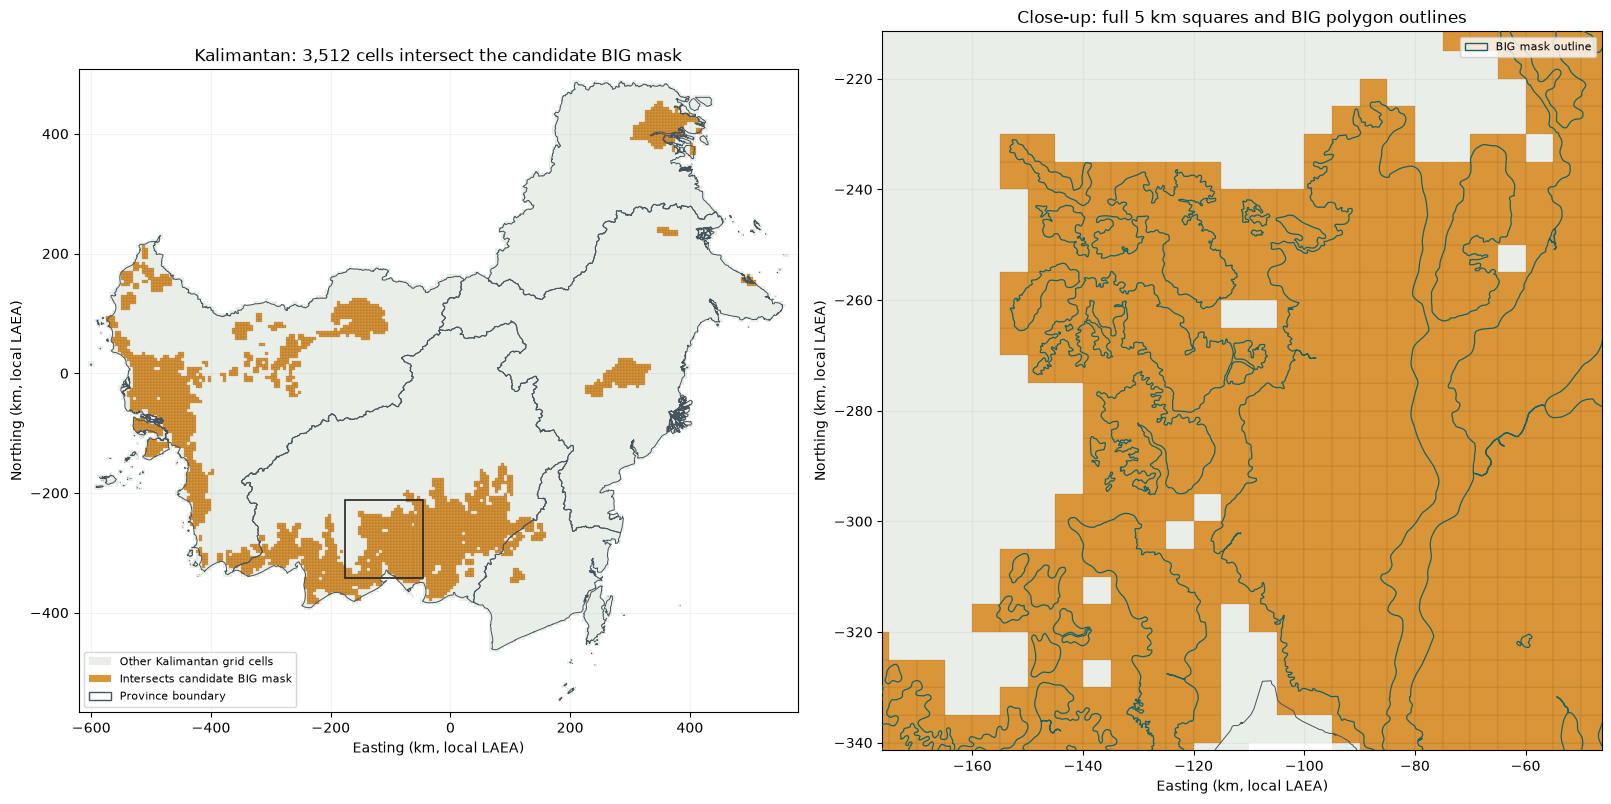

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
vertices_km = corners[:, :4, :] / 1000
for ax in axes:
    ax.add_collection(PolyCollection(vertices_km, facecolors="#e9eee9",
                                    edgecolors="none", zorder=1))
    ax.add_collection(PolyCollection(vertices_km[intersects_big], facecolors="#d99537",
                                    edgecolors="#81551f", linewidths=0.12, zorder=2))
    for province in provinces:
        plot_polygon(shapely.transform(province.simplify(100), lambda xy: xy / 1000),
                     ax=ax, add_points=False, facecolor="none",
                     edgecolor="#46545c", linewidth=0.7, zorder=3)
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (km, local LAEA)")
    ax.set_ylabel("Northing (km, local LAEA)")
    ax.grid(alpha=0.15)

axes[0].set_xlim(min_x / 1000 - 20, max_x / 1000 + 20)
axes[0].set_ylim(min_y / 1000 - 20, max_y / 1000 + 20)
axes[0].set_title(f"Kalimantan: {intersects_big.sum():,} cells intersect the candidate BIG mask")
zoom_x, zoom_y = np.array(to_grid.transform(113, -2.5)) / 1000
half_width = 65
zoom_bounds = (zoom_x-half_width, zoom_y-half_width, zoom_x+half_width, zoom_y+half_width)
axes[0].add_patch(Rectangle(zoom_bounds[:2], 2*half_width, 2*half_width,
                            fill=False, edgecolor="#222222", linewidth=1.2, zorder=4))
axes[1].set_xlim(zoom_bounds[0], zoom_bounds[2])
axes[1].set_ylim(zoom_bounds[1], zoom_bounds[3])
plot_polygon(shapely.transform(mapped_in_study, lambda xy: xy / 1000),
             ax=axes[1], add_points=False, facecolor="none", edgecolor="#12636a",
             linewidth=0.9, zorder=4)
axes[1].set_title("Close-up: full 5 km squares and BIG polygon outlines")
axes[0].legend(handles=[
    Patch(facecolor="#e9eee9", label="Other Kalimantan grid cells"),
    Patch(facecolor="#d99537", label="Intersects candidate BIG mask"),
    Patch(facecolor="none", edgecolor="#46545c", label="Province boundary"),
], loc="lower left", fontsize=8)
axes[1].legend(handles=[Patch(facecolor="none", edgecolor="#12636a", label="BIG mask outline")],
               loc="upper right", fontsize=8)
fig.savefig(OUTPUT_DIR / "study_grid_5km.png", dpi=180, facecolor="white")
plt.show()

## 6. Save this candidate grid and its decisions

Save all retained cells, not just flagged ones. The CSV carries attributes;
the GeoJSON carries matching full-square geometries in WGS84 for GIS viewers.
GeoJSON edges are defined by transformed corners; use the projected corner
columns and manifest CRS to reconstruct the exact study squares.
The manifest records source hashes, software versions, CRS, origin, rules,
and counts. Generated files live under the Git-ignored `data/interim/` folder.

These exports describe the spatial grid. The following section creates
in-memory daily FIRMS labels; it does not yet export them or attach predictors.

In [7]:
grid.to_csv(OUTPUT_DIR / "study_grid_5km.csv", index=False)
cells_ll = [transform(to_lonlat.transform, cell) for cell in cells]
geojson = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": row, "geometry": mapping(geometry)}
    for row, geometry in zip(grid.to_dict(orient="records"), cells_ll)
]}
(OUTPUT_DIR / "study_grid_5km.geojson").write_text(json.dumps(geojson), encoding="utf-8")
manifest = {
    "status": "candidate grid pending map and mask review",
    "cell_size_m": CELL_M,
    "grid_crs_proj": GRID_CRS_PROJ,
    "grid_crs_wkt": GRID_CRS.to_wkt(),
    "source_crs": "EPSG:4326 (GeoJSON longitude/latitude)",
    "lattice_origin_m": [0, 0],
    "row_direction": "northward; column direction eastward",
    "cell_id_rule": "kp5_c{grid_col}_r{grid_row}; signed integer lattice indices",
    "bounds_indices_stop_exclusive": {
        "col_start": int(col_start), "col_stop": int(col_stop),
        "row_start": int(row_start), "row_stop": int(row_stop),
    },
    "study_cell_rule": "positive-area overlap with dissolved five-province boundary; keep full squares",
    "big_mask_rule": "all downloaded BIG polygons, dissolved and intersected with province union",
    "big_flag_rule": "intersects, including boundary-only touches; no minimum fraction",
    "fraction_denominator_m2": CELL_M**2,
    "source_polygon_counts": {"provinces": len(province_features), "big": len(peat_features)},
    "counts": {k: int(v) for k, v in summary.items()},
    "province_union_area_km2": study_area.area / 1e6,
    "big_mask_area_in_provinces_km2": mapped_in_study.area / 1e6,
    "ground_edge_length_m": {"min": float(edge_m.min()), "max": float(edge_m.max())},
    "sources": [{"path": str(path.relative_to(ROOT)),
                 "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
                for path in [BOUNDARY_PATH, PEAT_PATH]],
    "software": {"numpy": np.__version__, "pandas": pd.__version__,
                 "shapely": shapely.__version__, "pyproj": pyproj.__version__,
                 "proj": pyproj.proj_version_str},
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
print("Saved:", OUTPUT_DIR.relative_to(ROOT))
print("study_grid_5km.csv, study_grid_5km.geojson, study_grid_5km.png, manifest.json")

Saved: data/interim/study_grid_5km
study_grid_5km.csv, study_grid_5km.geojson, study_grid_5km.png, manifest.json


## 7. Build validated chronological tables

Run this section without environment setup: it defaults to the local FIRMS ledger and the visible **2026-10-25 acquisition snapshot** below. This is a retrieval cutoff, not a study end date: observations remain bounded to 2020–2025. Override `FIRMS_LEDGER` or `PEATGUARD_AS_OF` when deliberately selecting another source ledger or snapshot. No detection filename or first/last hotspot date establishes complete coverage. Strict coverage and same-year maps are the defaults. `PEATGUARD_COVERAGE_POLICY=exclude_ineligible` and `PEATGUARD_MAP_POLICY=carry_forward` are explicit alternative research policies; exclusions and actual map years remain in the build.

The expanded research profile trains on 2020–2024 and tests on the full 2025 calendar year. There is no validation split or 2026 study data. The frozen 2025 test partition is prepared separately by default; fitting and development loading use training rows only. To explicitly prepare a shorter test interval, set both `PEATGUARD_HELD_OUT_START` and `PEATGUARD_HELD_OUT_END` within 2025. This creates a separate guarded partition and does not load test outcomes into this notebook. The full 2025 test interval is fixed in the study configuration. Weather mappings use training source masks only, with 10 km CHIRPS and 20 km ERA5 fallback limits. Source revisions change build identity; previous tables are retained.


In [ ]:
import json
import os
from pathlib import Path
import pandas as pd
from peatguard.study import load_study
from peatguard.datasets import prepare, CoverageError

# Visible defaults for the downloaded local snapshot; environment overrides are optional.
DEFAULT_AS_OF = "2026-10-25"
default_ledger = ROOT / "data/raw/Firms/intervals.json"
ledger = os.environ.get("FIRMS_LEDGER") or str(default_ledger)
cutoff = os.environ.get("PEATGUARD_AS_OF") or DEFAULT_AS_OF
if not Path(ledger).is_file():
    raise FileNotFoundError(f"FIRMS ledger not found: {ledger}. Import the source files first or set FIRMS_LEDGER.")
study = load_study(root=ROOT, profile=os.environ.get("PEATGUARD_PROFILE", "expanded"),
                   start=os.environ.get("PEATGUARD_START"), end=os.environ.get("PEATGUARD_END", "latest"), as_of=cutoff)
print("FIRMS ledger:", ledger)
print("Acquisition cutoff:", study.as_of.isoformat())
print("Study interval:", study.start, "through", study.end)
print("Chronological splits:", study.profile_config["splits"])
held_start, held_end = os.environ.get("PEATGUARD_HELD_OUT_START"), os.environ.get("PEATGUARD_HELD_OUT_END")
if bool(held_start) != bool(held_end):
    raise ValueError("Both held-out boundaries must be explicit.")
build_directory = None
quality_report = None
try:
    build_directory = prepare(study, ledger,
        map_policy=os.environ.get("PEATGUARD_MAP_POLICY", "strict_same_year"),
        coverage_policy=os.environ.get("PEATGUARD_COVERAGE_POLICY", "require_complete"),
        held_out_interval=(held_start, held_end) if held_start else None)
except CoverageError as error:
    quality_report = error.report_path
    quality = json.loads(quality_report.read_text())
    print("Preparation blocked by incomplete data coverage. No training or test tables were published.")
    print("Coverage report:", quality_report)
    display(pd.DataFrame.from_dict(quality["splits"], orient="index")[[
        "requested_start", "requested_end", "requested_rows", "eligible_rows", "excluded_rows", "excluded_reason_counts"
    ]])
else:
    print("Prepared research build:", build_directory)
    print("No model was trained. Run the export cell below to create the named train/test files for base_models.ipynb.")


FIRMS ledger: /Users/raynanda/Documents/Development/kalimantan-peatguard/data/raw/Firms/intervals.json
Acquisition cutoff: 2026-10-25T23:59:59.999999+00:00
Study interval: 2020-01-01 through 2025-12-31
Chronological splits: {'train': ['2020-01-01', '2024-12-31'], 'test': ['2025-01-01', '2025-12-31']}


## 8. Inspect development coverage only

The combined table and exclusion ledger are audit artifacts; they may contain a deliberately prepared held-out partition. Ordinary notebook loading opens training only in the active profile. Quality metadata reports structural eligibility, not test label distributions. The fixed vocabulary is IGBP 1–17; training-only ranges and explicit constant-feature flags are saved beside the tables. No automatic training or scoring runs here. If preparation was blocked, this section reports that state without opening a previous build.


In [ ]:
from peatguard.datasets import load_build
if build_directory is None:
    print("No prepared build is available. Resolve the coverage issues reported above, then rerun section 7.")
else:
    contract, development = load_build(build_directory)
    print("Build:", contract["build_id"])
    print("Predictor columns:", contract["predictors"])
    for role, frame in development.items():
        print(role, "eligible rows:", len(frame), "dates:", frame.acq_date.min(), "to", frame.acq_date.max())
    print("Candidate-mask status:", contract["descriptor"]["scientific_status"])


## 9. Export named train and test files

Copy each prepared partition to `data/interim/model_table/` with its years in the filename. The active full study produces `train_2020_2024.parquet` and `test_2025.parquet`; the original 2020–2023/2024 files remain unchanged. `prepared_dataset.json` records the build and checksums. This copies held-out files without inspecting their outcomes. The baseline notebook explicitly imports both partitions for later modeling; use training only for exploration and model choices.


In [ ]:
import shutil
import tempfile
from peatguard.inventory import sha256

exported_paths = {}
if build_directory is None:
    print("No dataset exported. Resolve the preparation errors above first.")
else:
    # Reload the manifest so reruns never export an older in-memory contract.
    export_contract = json.loads((build_directory / "manifest.json").read_text())
    export_directory = ROOT / "data/interim/model_table"
    export_directory.mkdir(parents=True, exist_ok=True)
    export_metadata = {"build_directory": str(build_directory.relative_to(ROOT)),
                       "build_id": export_contract["build_id"], "partitions": {}}
    # Stage and checksum every copy before publishing the convenience files.
    with tempfile.TemporaryDirectory(prefix=".export-", dir=export_directory) as temporary:
        staged = Path(temporary)
        for role, info in export_contract["partitions"].items():
            dates = export_contract["quality"]["splits"][role]
            first_year = dates["requested_start"][:4]
            last_year = dates["requested_end"][:4]
            years = first_year if first_year == last_year else f"{first_year}_{last_year}"
            filename = f"{role}_{years}.parquet"
            source = build_directory / info["file"]
            expected_hash = export_contract["files"][info["file"]]
            if sha256(source) != expected_hash:
                raise ValueError(f"Prepared partition checksum mismatch: {role}")
            shutil.copyfile(source, staged / filename)
            if sha256(staged / filename) != expected_hash:
                raise ValueError(f"Export checksum mismatch: {role}")
            exported_paths[role] = export_directory / filename
            export_metadata["partitions"][role] = {
                "file": filename, "sha256": expected_hash, "rows": info["rows"],
                "start": dates["requested_start"], "end": dates["requested_end"],
            }
        (staged / "prepared_dataset.json").write_text(json.dumps(export_metadata, indent=2) + "\n")
        for role, destination in exported_paths.items():
            (staged / destination.name).replace(destination)
        # Publish provenance last. Older research files are never deleted.
        (staged / "prepared_dataset.json").replace(export_directory / "prepared_dataset.json")
    for role, path in exported_paths.items():
        print(f"{role}: {path.relative_to(ROOT)}")
